# Gaussian processes: inspect smoothness, noise, and joint uncertainty

A Gaussian process defines a joint law over function values. Its kernel controls how values at different inputs move together; its observation-noise model controls how tightly it follows the data.

We use a known sine function, leave a gap in the training locations, and query both inside and outside the observed domain. This makes interpolation uncertainty and kernel assumptions visible. All posteriors below condition on specified or fitted hyperparameters; they do not integrate over hyperparameter uncertainty. [GP contracts](../docs/gaussian_processes.md).

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from convexity.math import gaussian_processes as gp

rng = np.random.default_rng(42)
plt.rcParams.update({"figure.figsize": (10, 3.8), "axes.grid": True,
                     "grid.alpha": .18, "figure.dpi": 110})

## A gap distinguishes observations from information

The training response is $\sin(1.5x)$ plus independent noise with standard deviation 0.12. We omit inputs near zero. A posterior can remain smooth through the gap while becoming less certain there.

Feature arrays have shape `(rows, features)` and the response is scalar. The kernel amplitude is a variance multiplier, and the length scale is measured in input units.

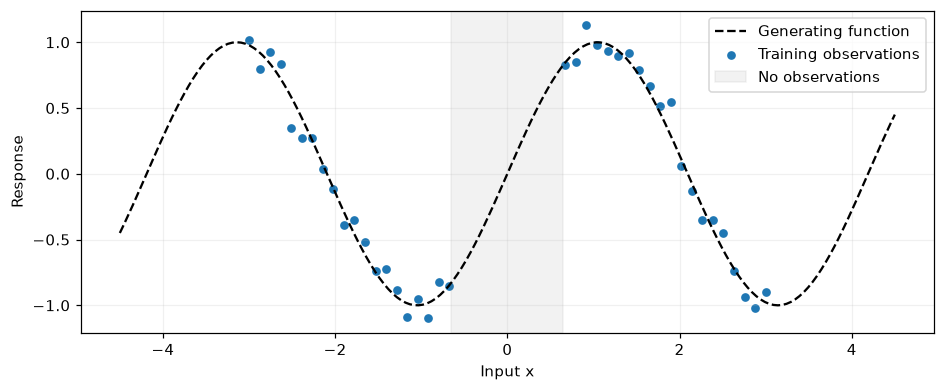

In [2]:
x_all = np.linspace(-3, 3, 50)
x = x_all[np.abs(x_all)>.65, None]
truth = lambda values: np.sin(1.5*values)
y = truth(x[:, 0]) + rng.normal(0, .12, len(x))
query = np.linspace(-4.5, 4.5, 180)[:, None]
fig, ax = plt.subplots()
ax.plot(query[:, 0], truth(query[:, 0]), "k--", label="Generating function")
ax.scatter(x[:, 0], y, s=22, label="Training observations")
ax.axvspan(-.65, .65, alpha=.1, color="gray", label="No observations")
ax.set(xlabel="Input x", ylabel="Response")
ax.legend()
plt.show()

## Hold the length scale fixed before asking an optimizer to choose it

Short length scales allow rapid variation and weak extrapolation from nearby observations. Long length scales enforce stronger similarity over distance. Compare three fixed kernels on the same data before fitting hyperparameters.

The marginal likelihood balances fit and covariance complexity. It can prefer a different scale when the noise assumption changes, and it is an in-sample model criterion rather than an independent predictive score.

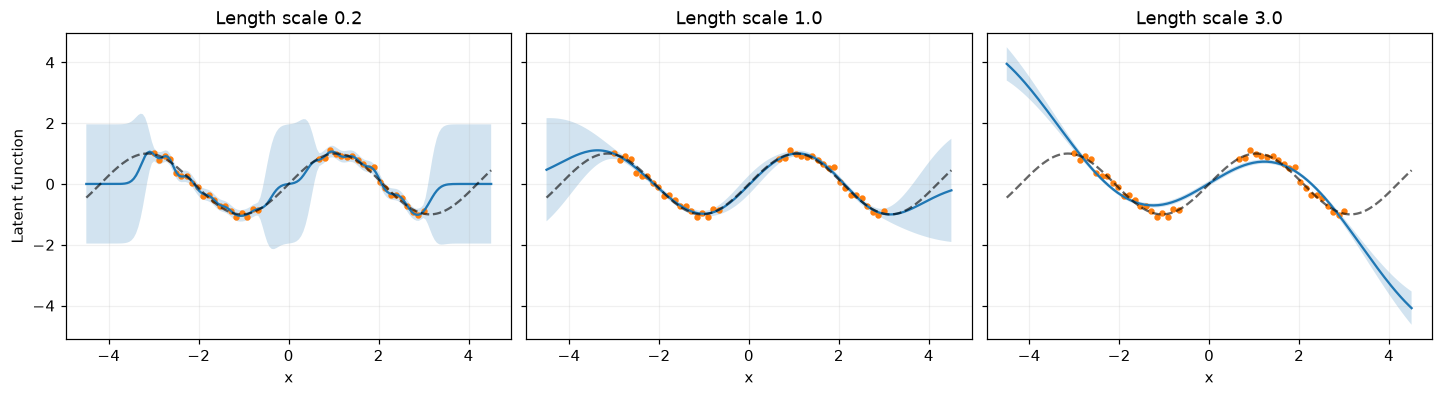

,length scale,log marginal likelihood
0,0.2,-13.107254
1,1.0,14.364979
2,3.0,-102.775885


In [3]:
fixed_models = {length: gp.GaussianProcessRegressor(gp.Constant(1.)*gp.RBF(length),
                   alpha=.12**2, optimize=False).fit(x, y) for length in (.2, 1., 3.)}
fig, axes = plt.subplots(1, 3, figsize=(13, 3.5), sharey=True, layout="constrained")
for ax, (length, model) in zip(axes, fixed_models.items()):
    posterior = model.posterior(query)
    bounds = posterior.interval(.95)
    ax.fill_between(query[:, 0], bounds[:, 0], bounds[:, 1], alpha=.2)
    ax.plot(query[:, 0], posterior.mean)
    ax.plot(query[:, 0], truth(query[:, 0]), "k--", alpha=.6)
    ax.scatter(x[:, 0], y, s=10)
    ax.set(title=f"Length scale {length}", xlabel="x")
axes[0].set_ylabel("Latent function")
plt.show()
pd.DataFrame({"length scale": list(fixed_models), "log marginal likelihood": [
    model.log_marginal_likelihood() for model in fixed_models.values()]})

## Fit the covariance and separate latent from observation uncertainty

We fit a Matérn kernel with fixed smoothness $\nu=2.5$. `alpha=.12**2` is the known noise variance used in conditioning; it is not automatically added at future query points. `posterior(..., noise_variance=.12**2)` adds independent future measurement noise explicitly.

The two posteriors share a mean. The observation band is wider because a future measurement contains fresh noise. Both are **pointwise** bands; neither states that an entire curve lies inside with 95% probability.

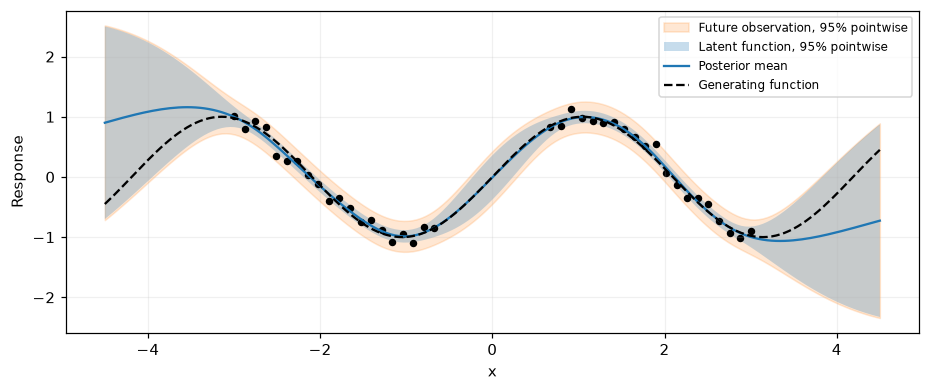

,parameter,fitted value
0,k1__constant_value,1.373023
1,k2__length_scale,1.831467


In [4]:
kernel = gp.Constant(1., bounds=(.05, 10))*gp.Matern(1., nu=2.5, bounds=(.1, 5))
model = gp.GaussianProcessRegressor(kernel, alpha=.12**2, restarts=1, seed=7).fit(x, y)
latent = model.posterior(query)
observed = model.posterior(query, noise_variance=.12**2)
latent_bounds, observation_bounds = latent.interval(.95), observed.interval(.95)
fig, ax = plt.subplots()
ax.fill_between(query[:, 0], observation_bounds[:, 0], observation_bounds[:, 1], alpha=.18, color="tab:orange", label="Future observation, 95% pointwise")
ax.fill_between(query[:, 0], latent_bounds[:, 0], latent_bounds[:, 1], alpha=.25, label="Latent function, 95% pointwise")
ax.plot(query[:, 0], latent.mean, label="Posterior mean")
ax.plot(query[:, 0], truth(query[:, 0]), "k--", label="Generating function")
ax.scatter(x[:, 0], y, s=15, color="black")
ax.set(xlabel="x", ylabel="Response")
ax.legend(fontsize=8)
plt.show()
pd.DataFrame({"parameter": model.kernel.parameter_names, "fitted value": np.exp(model.kernel.theta)})

## Joint samples reveal dependence hidden by pointwise bands

`posterior.sample` draws every query coordinate jointly. Neighbouring points therefore move together according to the posterior covariance. Independent marginal draws could have the same pointwise intervals but would represent very different curves.

The matrix is ordered by query row. Inspect its behaviour through the data gap and near the boundaries. Sampling here returns function values on this finite grid, not an independently specified continuous-path law.

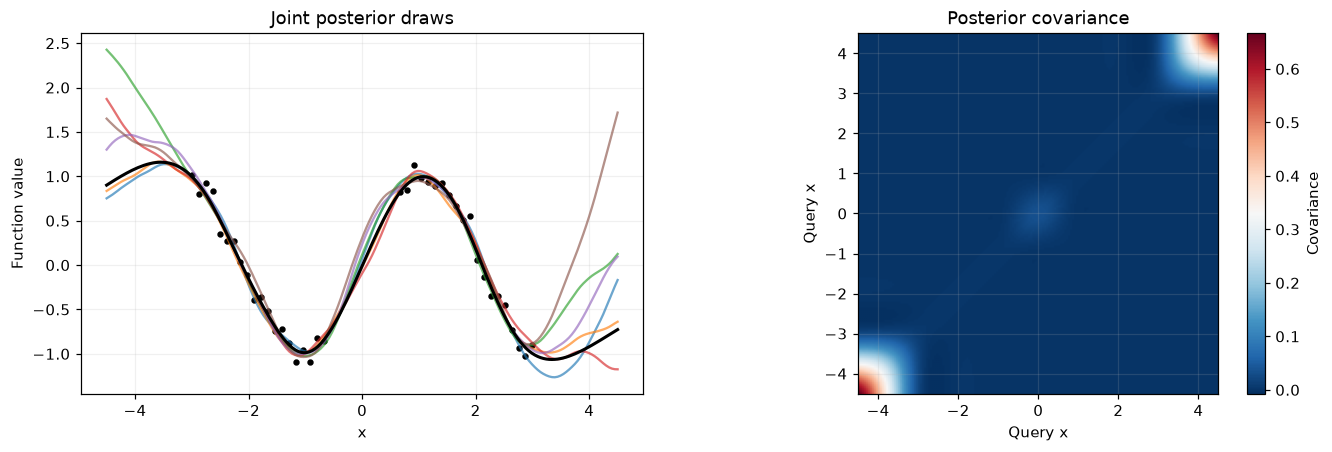

In [5]:
draws = latent.sample(6, rng=np.random.default_rng(7))
fig, axes = plt.subplots(1, 2, figsize=(12, 4), layout="constrained")
axes[0].plot(query[:, 0], draws.T, alpha=.65)
axes[0].plot(query[:, 0], latent.mean, color="black", linewidth=2)
axes[0].scatter(x[:, 0], y, s=10, color="black")
axes[0].set(xlabel="x", ylabel="Function value", title="Joint posterior draws")
image = axes[1].imshow(latent.covariance, origin="lower", cmap="RdBu_r",
                       extent=[query[0, 0], query[-1, 0], query[0, 0], query[-1, 0]])
axes[1].set(xlabel="Query x", ylabel="Query x", title="Posterior covariance")
fig.colorbar(image, ax=axes[1], label="Covariance")
plt.show()

## Unknown noise can compete with kernel smoothness

Adding `WhiteNoise` makes its variance a fitted kernel parameter. This component is already present in the returned predictive covariance; adding it again with `noise_variance` would double-count it. Its cross-covariance between separate observations is zero even at matching input coordinates.

Compare fitted noise with the known generating variance, and inspect both the data-gap and extrapolation errors. A good marginal likelihood does not ensure that the selected kernel extrapolates the sine wave correctly.

In [6]:
noisy_kernel = gp.Constant(1., bounds=(.05, 10))*gp.RBF(1., bounds=(.1, 5))
noisy_kernel += gp.WhiteNoise(.02, bounds=(1e-4, .5))
noisy_model = gp.GaussianProcessRegressor(noisy_kernel, alpha=1e-10, restarts=1, seed=8).fit(x, y)
display(pd.DataFrame({"parameter": noisy_model.kernel.parameter_names,
                      "fitted value": np.exp(noisy_model.kernel.theta)}))
regions = {"data gap": np.abs(query[:, 0])<.65,
           "observed domain outside gap": (np.abs(query[:, 0])>=.65)&(np.abs(query[:, 0])<=3),
           "extrapolation": np.abs(query[:, 0])>3}
pd.DataFrame([{ "region": region, "model": label,
               "RMSE against generating function": np.sqrt(np.mean((fitted.predict(query[mask])-truth(query[mask, 0]))**2))}
              for region, mask in regions.items()
              for label, fitted in {"Known noise, Matérn": model, "Learned noise, RBF": noisy_model}.items()])

,parameter,fitted value
0,k1__k1__constant_value,1.256805
1,k1__k2__length_scale,1.357963
2,k2__noise_level,0.010553


,region,model,RMSE against generating function
0,data gap,"Known noise, Matérn",0.015303
1,data gap,"Learned noise, RBF",0.054538
2,observed domain outside gap,"Known noise, Matérn",0.033799
3,observed domain outside gap,"Learned noise, RBF",0.030681
4,extrapolation,"Known noise, Matérn",0.675148
5,extrapolation,"Learned noise, RBF",0.607035


Try changing the gap width or replacing the generating curve with a periodic function over several cycles. A periodic kernel can express that structure, while a stationary RBF need not extrapolate it. This implementation is dense scalar-response GP regression; multidimensional inputs are supported, but jointly modelled multiple responses and hyperparameter posteriors are separate capabilities.